In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
hsp_df = pd.read_csv('hospital_readmissions.csv')
hsp_df.head()

,age,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,diag_1,diag_2,diag_3,glucose_test,A1Ctest,change,diabetes_med,readmitted
0,[70-80),8,72,1,18,2,0,0,Missing,Circulatory,Respiratory,Other,no,no,no,yes,no
1,[70-80),3,34,2,13,0,0,0,Other,Other,Other,Other,no,no,no,yes,no
2,[50-60),5,45,0,18,0,0,0,Missing,Circulatory,Circulatory,Circulatory,no,no,yes,yes,yes
3,[70-80),2,36,0,12,1,0,0,Missing,Circulatory,Other,Diabetes,no,no,yes,yes,yes
4,[60-70),1,42,0,7,0,0,0,InternalMedicine,Other,Circulatory,Respiratory,no,no,no,yes,no


In [3]:
hsp_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   age                25000 non-null  object
 1   time_in_hospital   25000 non-null  int64 
 2   n_lab_procedures   25000 non-null  int64 
 3   n_procedures       25000 non-null  int64 
 4   n_medications      25000 non-null  int64 
 5   n_outpatient       25000 non-null  int64 
 6   n_inpatient        25000 non-null  int64 
 7   n_emergency        25000 non-null  int64 
 8   medical_specialty  25000 non-null  object
 9   diag_1             25000 non-null  object
 10  diag_2             25000 non-null  object
 11  diag_3             25000 non-null  object
 12  glucose_test       25000 non-null  object
 13  A1Ctest            25000 non-null  object
 14  change             25000 non-null  object
 15  diabetes_med       25000 non-null  object
 16  readmitted         25000 non-null  objec

In [4]:
hsp_df.rename(columns={'diag_1':'primary_diagnosis','diag_2':'sec_diagnosis',
                       'diag_3':'additional_sec_diag','change':'med_change','A1Ctest':'HbA1ctest'},inplace=True)
hsp_df.head()

,age,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,primary_diagnosis,sec_diagnosis,additional_sec_diag,glucose_test,HbA1ctest,med_change,diabetes_med,readmitted
0,[70-80),8,72,1,18,2,0,0,Missing,Circulatory,Respiratory,Other,no,no,no,yes,no
1,[70-80),3,34,2,13,0,0,0,Other,Other,Other,Other,no,no,no,yes,no
2,[50-60),5,45,0,18,0,0,0,Missing,Circulatory,Circulatory,Circulatory,no,no,yes,yes,yes
3,[70-80),2,36,0,12,1,0,0,Missing,Circulatory,Other,Diabetes,no,no,yes,yes,yes
4,[60-70),1,42,0,7,0,0,0,InternalMedicine,Other,Circulatory,Respiratory,no,no,no,yes,no


In [5]:
#converting age column to categorical data
#checking for the unique values in the age column
print(hsp_df['age'].unique())

#creating a new column called age_cat
hsp_df['age_cat'] = hsp_df['age'].replace({'[70-80)':'senior-old age',
                                           '[50-60)':'late-middle age','[60-70)':'mid-old age',
                                           '[40-50)':'early-middle age','[80-90)':'very senior-old','[90-100)':'centenarians'})

print('\n')
#converting column type to categorical data type
hsp_df['age_cat'] = hsp_df['age_cat'].astype('category')
print('dtype :', hsp_df['age_cat'].dtype)

#viewing age and age_cat columns
hsp_df[['age', 'age_cat']]

['[70-80)' '[50-60)' '[60-70)' '[40-50)' '[80-90)' '[90-100)']


dtype : category


,age,age_cat
0,[70-80),senior-old age
1,[70-80),senior-old age
2,[50-60),late-middle age
3,[70-80),senior-old age
4,[60-70),mid-old age
...,...,...
24995,[80-90),very senior-old
24996,[80-90),very senior-old
24997,[70-80),senior-old age
24998,[70-80),senior-old age


In [6]:
#drop age column
hsp_df.drop('age', axis=1, inplace=True)

#changing data type to the correct data type
# Columns to be converted to categorical datatype
cols_to_convert = ['medical_specialty', 'primary_diagnosis', 'sec_diagnosis', 'additional_sec_diag', 'glucose_test', 'HbA1ctest', 'med_change', 'diabetes_med', 'readmitted']

# Convert columns to categorical datatype
hsp_df[cols_to_convert] = hsp_df[cols_to_convert].astype('category')
#checking data type
hsp_df.dtypes

time_in_hospital          int64
n_lab_procedures          int64
n_procedures              int64
n_medications             int64
n_outpatient              int64
n_inpatient               int64
n_emergency               int64
medical_specialty      category
primary_diagnosis      category
sec_diagnosis          category
additional_sec_diag    category
glucose_test           category
HbA1ctest              category
med_change             category
diabetes_med           category
readmitted             category
age_cat                category
dtype: object

In [7]:
#checking for duplicates
hsp_df.duplicated().sum()

np.int64(0)

In [8]:
#viewing the unique values of each column to check for inconsistent data
cols = hsp_df.columns

for c in cols:
    print(c)
    print('\n',hsp_df[c].unique())

time_in_hospital

 [ 8  3  5  2  1  4  7 10  6 12 11  9 14 13]
n_lab_procedures

 [ 72  34  45  36  42  51  44  19  67  37  35  69  60  73  52   9  16  62
  54  58  40  23  32  65   1  47  39  59  68  66  43  30  46  48   5  24
  70  25  29  49  53  94  18  61  11  33  28  83  50  71  86  38   3  41
  31  55  56  27  64  82  26  90  21   2  20  17  78 102  75  15   8   7
  76  63  57  10   4  22  91  74  14  13  89  79  81  84  80   6  77  12
 108  88  92  93 101  97 100  85  95  87  98  96  99 103 111 106 113 109
 105]
n_procedures

 [1 2 0 6 3 5 4]
n_medications

 [18 13 12  7 10 21 16  6 26 20 11 27 15  8 22 17 14 28  5 24  9 19  1 25
 32  3 31 23 39 34 40  4 38  2 33 56 44 29 46 30 47 41 35 36 50 49 54 57
 60 37 61 52 51 42 53 43 45 59 62 79 63 55 65 48 58 69 68 72 75 64]
n_outpatient

 [ 2  0  1  3  7  5  4  6  9  8 11 10 15 21 13 12 27 16 14 33 20 18 23]
n_inpatient

 [ 0  2  3  1  6  9  7  4  5  8 10 11 14 12 15 13]
n_emergency

 [ 0  1 10  2  3  4  5  7  6 12  8 16 28 18 11  9 

In [9]:
hsp_df.describe()

,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency
count,25000.00000,25000.00000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,4.45332,43.24076,1.352360,16.252400,0.366400,0.615960,0.186600
std,3.00147,19.81862,1.715179,8.060532,1.195478,1.177951,0.885873
min,1.00000,1.00000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2.00000,31.00000,0.000000,11.000000,0.000000,0.000000,0.000000
50%,4.00000,44.00000,1.000000,15.000000,0.000000,0.000000,0.000000
75%,6.00000,57.00000,2.000000,20.000000,0.000000,1.000000,0.000000
max,14.00000,113.00000,6.000000,79.000000,33.000000,15.000000,64.000000


In [10]:
hsp_df.describe(exclude=[np.number])

,medical_specialty,primary_diagnosis,sec_diagnosis,additional_sec_diag,glucose_test,HbA1ctest,med_change,diabetes_med,readmitted,age_cat
count,25000,25000,25000,25000,25000,25000,25000,25000,25000,25000
unique,7,8,8,8,3,3,2,2,2,6
top,Missing,Circulatory,Other,Other,no,no,no,yes,no,senior-old age
freq,12382,7824,9056,9107,23625,20938,13497,19228,13246,6837


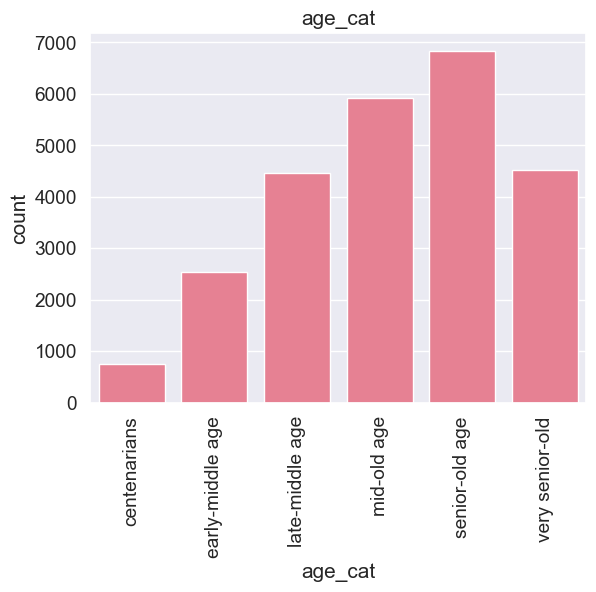

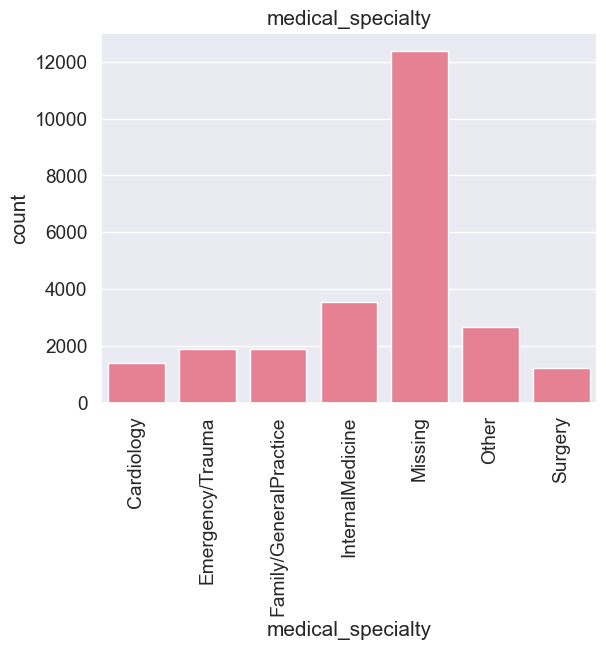

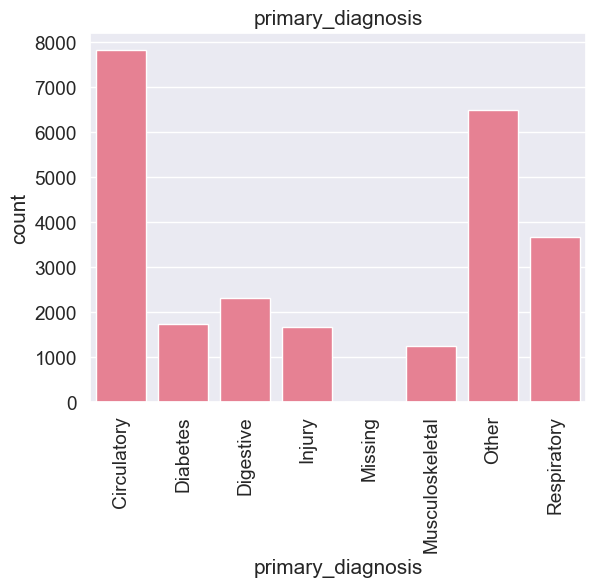

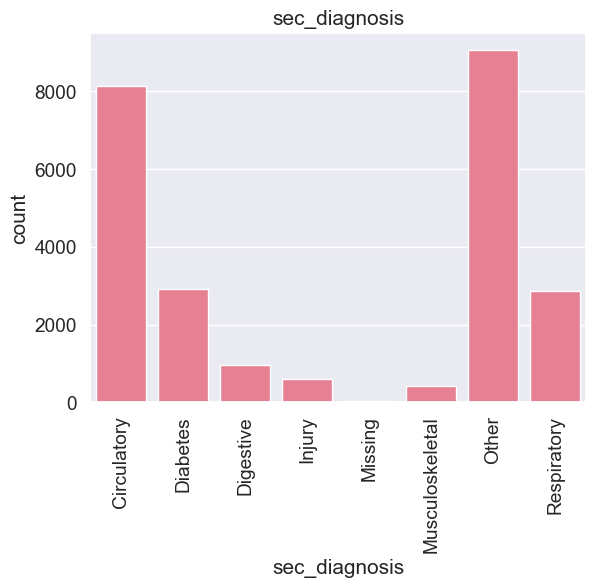

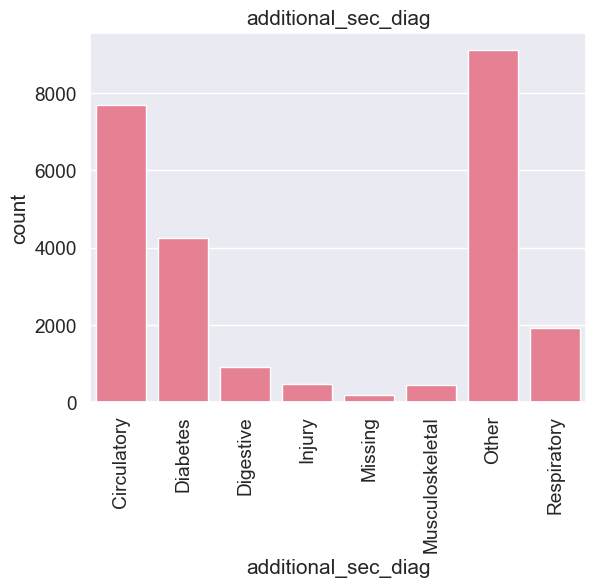

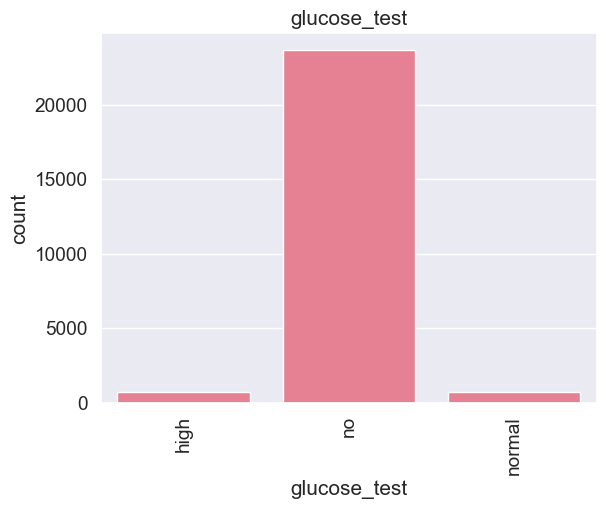

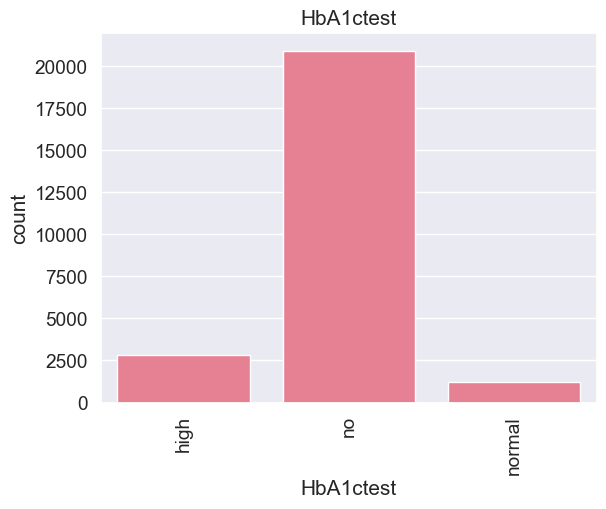

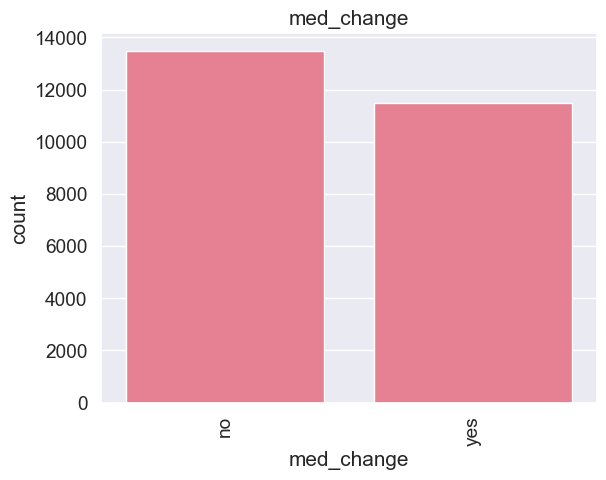

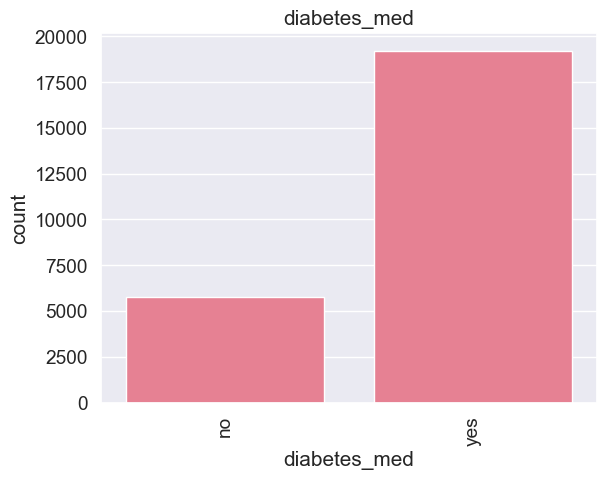

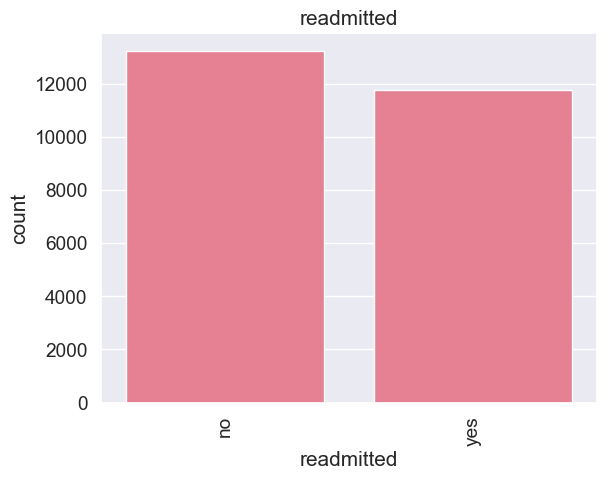

In [11]:
columns = ['age_cat', 'medical_specialty', 'primary_diagnosis',
           'sec_diagnosis', 'additional_sec_diag','glucose_test','HbA1ctest','med_change','diabetes_med','readmitted']

sns.set(style='darkgrid',font_scale=1.25)
sns.set_palette('husl',3)

def plot_cat_count():
    for c in columns:
        sns.countplot(x=c, data=hsp_df)
        plt.title(c)
        plt.xticks(rotation=90)
        plt.show()

plot_cat_count()

In [12]:
df = hsp_df.groupby('age_cat', observed=False)['primary_diagnosis'].value_counts(normalize=True,sort=True).to_frame().unstack()
df

proportion                                          \
primary_diagnosis Circulatory  Diabetes Digestive    Injury   Missing   
age_cat                                                                 
centenarians         0.304000  0.045333  0.100000  0.088000  0.000000   
early-middle age     0.199052  0.145735  0.107030  0.063981  0.000000   
late-middle age      0.282120  0.088275  0.099281  0.061321  0.000000   
mid-old age          0.331811  0.065111  0.093692  0.067648  0.000169   
senior-old age       0.349861  0.056311  0.085564  0.064941  0.000146   
very senior-old      0.328167  0.040080  0.089017  0.071081  0.000443   

                                                         
primary_diagnosis Musculoskeletal     Other Respiratory  
age_cat                                                  
centenarians             0.010667  0.293333    0.158667  
early-middle age         0.039494  0.296209    0.148499  
late-middle age          0.051662  0.261456    0.155885  
mid-old age              0.063081  0.237105    0.141383  
senior-old age           0.054556  0.247623    0.140998  
very senior-old          0.037201  0.281001    0.153012

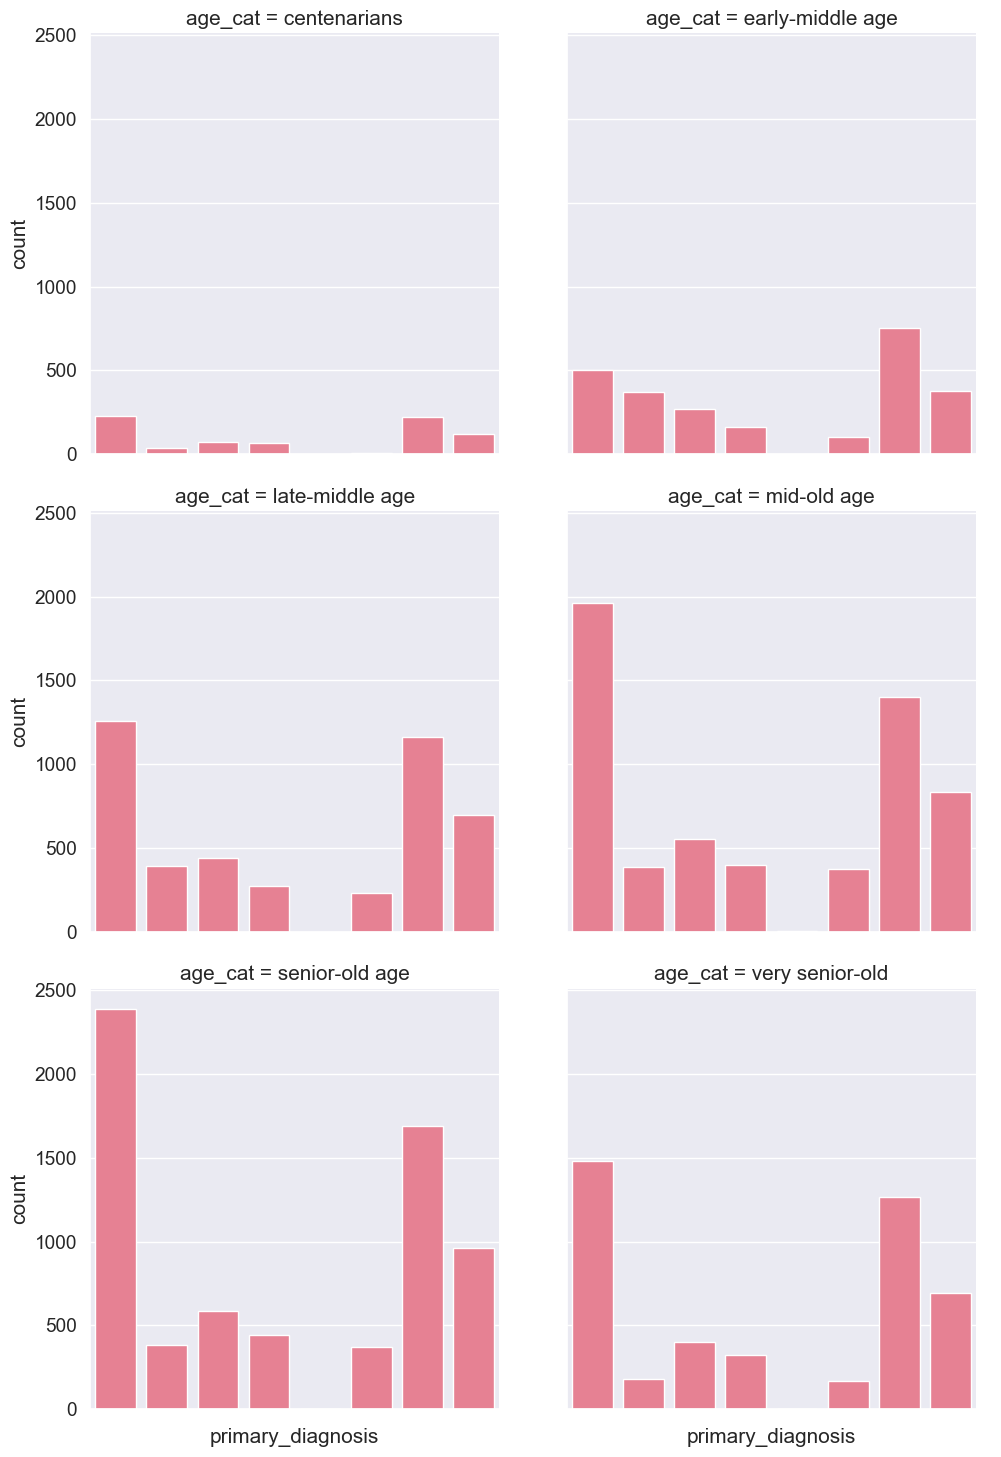

In [13]:
g = sns.catplot(x='primary_diagnosis',col='age_cat', kind='count', data=hsp_df, col_wrap=2)
g.set_xticklabels(rotation=90)
plt.show()

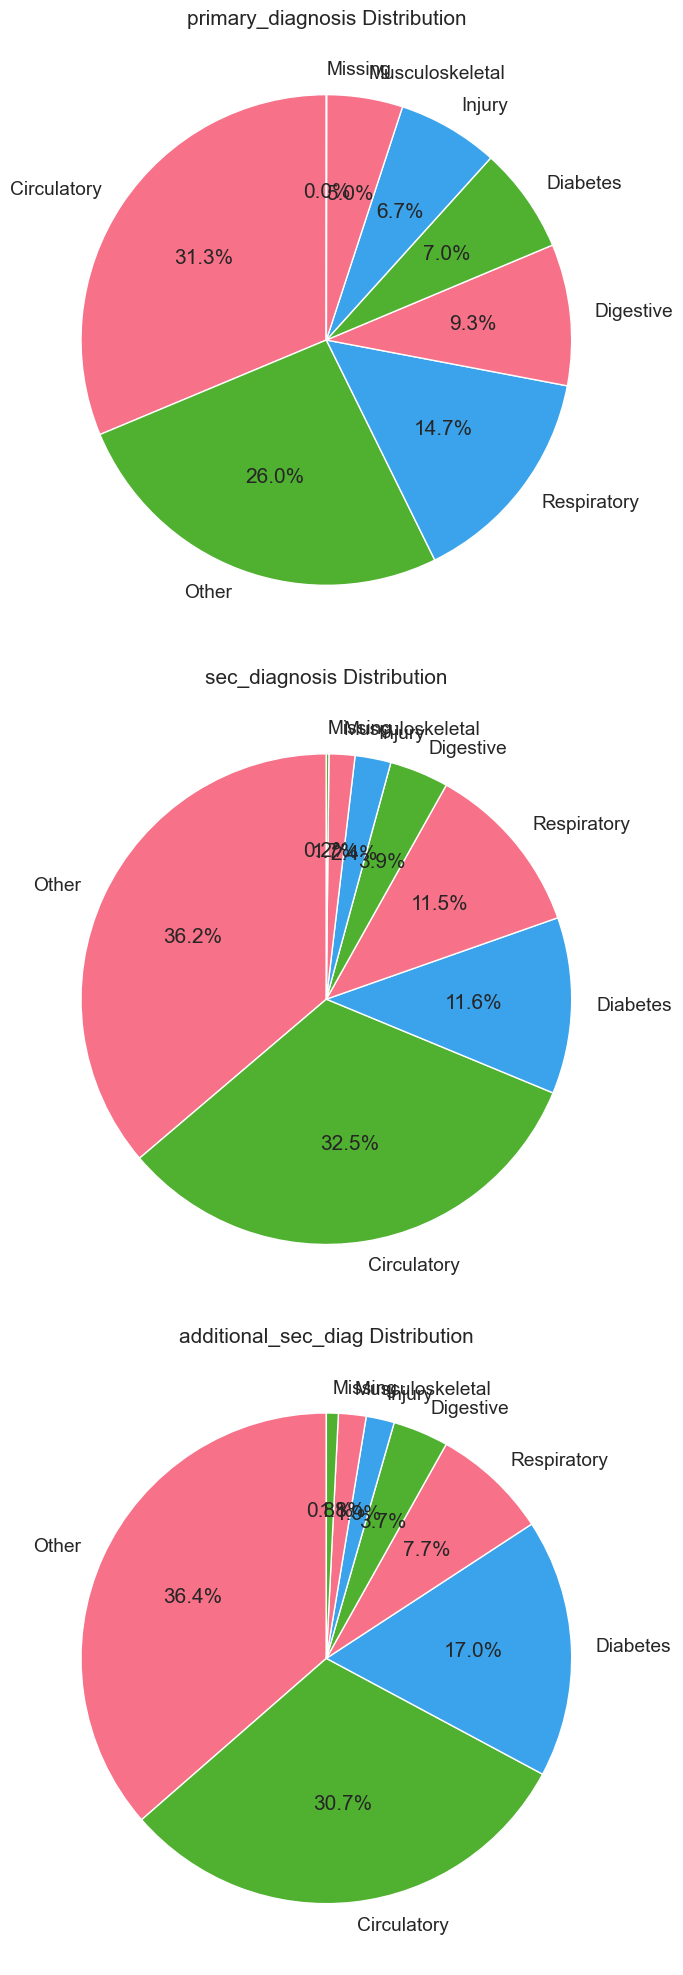

In [14]:
cat_vars = ['primary_diagnosis','sec_diagnosis','additional_sec_diag']

fig,axs = plt.subplots(nrows=3, ncols=1, figsize=(25,20))

for i, var in enumerate(cat_vars):
    if i < len(axs.flat):
        cat_counts = hsp_df[var].value_counts()
        axs.flat[i].pie(cat_counts, labels=cat_counts.index, autopct='%1.1f%%', startangle=90)
        axs.flat[i].set_title(f'{var} Distribution')

fig.tight_layout()
plt.show()


In [15]:
diabetes_pt = hsp_df[(hsp_df['primary_diagnosis'] == 'Diabetes') | (hsp_df['sec_diagnosis'] == 'Diabetes') |
        (hsp_df['additional_sec_diag'] == 'Diabetes')]
diabetes_pt.head()

,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,primary_diagnosis,sec_diagnosis,additional_sec_diag,glucose_test,HbA1ctest,med_change,diabetes_med,readmitted,age_cat
3,2,36,0,12,1,0,0,Missing,Circulatory,Other,Diabetes,no,no,yes,yes,yes,senior-old age
12,8,67,0,21,0,0,0,Other,Diabetes,Circulatory,Other,no,normal,no,yes,no,senior-old age
14,2,73,1,26,0,0,0,InternalMedicine,Circulatory,Other,Diabetes,no,no,no,yes,no,very senior-old
16,3,52,0,10,0,0,0,Other,Circulatory,Other,Diabetes,no,no,no,yes,yes,senior-old age
18,7,72,0,13,0,0,0,InternalMedicine,Diabetes,Other,Other,no,high,no,yes,yes,early-middle age


In [16]:
non_diabetes_pt = hsp_df[~((hsp_df['primary_diagnosis'] == 'Diabetes') | (hsp_df['sec_diagnosis'] == 'Diabetes') |
        (hsp_df['additional_sec_diag'] == 'Diabetes'))]

print('number of non-DM patient: ',len(non_diabetes_pt.index))

print ('number of DM patient: ',len(diabetes_pt.index))

number of non-DM patient:  16212
number of DM patient:  8788


In [17]:
#value couunts of DM patients readmitted
diabetes_pt['readmitted'].value_counts(normalize=True)

readmitted
no     0.534706
yes    0.465294
Name: proportion, dtype: float64

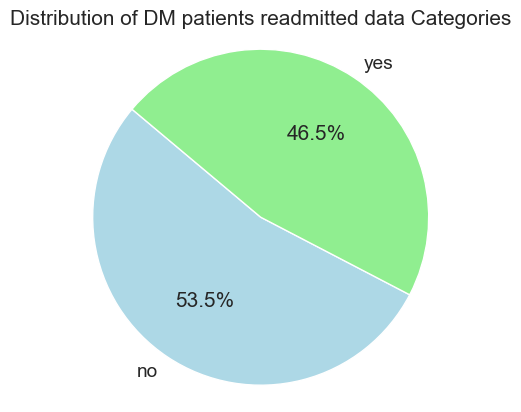

In [18]:
readmitted_data = {
    'no' : 0.534706,
    'yes' : 0.465294
}

fig, ax = plt.subplots()

labels = [f"{status}" for status in readmitted_data.keys()]
sizes = list(readmitted_data.values())

colors = ['lightblue', 'lightgreen']

ax.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=140)

ax.axis('equal')

plt.title('Distribution of DM patients readmitted data Categories')

plt.show()

In [19]:
non_diabetes_pt['readmitted'].value_counts(normalize=True)

readmitted
no     0.527202
yes    0.472798
Name: proportion, dtype: float64

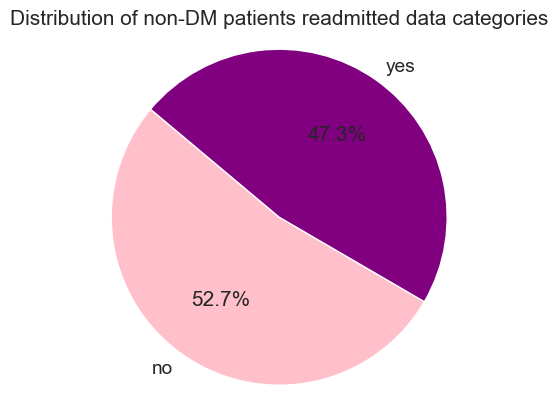

In [20]:
readmitted_data = {
    'no' : 0.527202,
    'yes' : 0.472798
}

fig, ax = plt.subplots()

labels = [f"{status}" for status in readmitted_data.keys()]
sizes = list(readmitted_data.values())

colors = ['pink', 'purple']

ax.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=140)

ax.axis('equal')

plt.title('Distribution of non-DM patients readmitted data categories')

plt.show()

In [21]:
pd.set_option('display.max_rows', 64)
hsp_df.groupby(['primary_diagnosis','sec_diagnosis','additional_sec_diag'], observed=False)['readmitted'].count().to_frame().unstack()

readmitted                            \
additional_sec_diag               Circulatory Diabetes Digestive Injury   
primary_diagnosis sec_diagnosis                                           
Circulatory       Circulatory            1724      877        48     66   
                  Diabetes                394       28        12      8   
                  Digestive                26        6        10      0   
                  Injury                   70       21         3     14   
                  Missing                   3        0         0      0   
                  Musculoskeletal           9       11         2      1   
                  Other                   595      381        35     18   
                  Respiratory             378      145        16     15   
Diabetes          Circulatory             133       10        13      6   
                  Diabetes                  2        1         2      0   
                  Digestive                13        2        13      2   
                  Injury                    4        0         1      2   
                  Missing                   0        0         0      0   
                  Musculoskeletal          18        0         0      2   
                  Other                   237       25        46     11   
                  Respiratory              35        1         3      1   
Digestive         Circulatory             121       85        39      4   
                  Diabetes                 99        3        38      1   
                  Digestive                60       92        81      3   
                  Injury                    8        3         7      1   
                  Missing                   0        1         0      0   
                  Musculoskeletal           3        4         2      0   
                  Other                   206      174       129     13   
                  Respiratory              56       26        21      2   
Injury            Circulatory             118       74         1     16   
                  Diabetes                 62        5         2      6   
                  Digestive                10       10         6      2   
                  Injury                   36       17         2     27   
                  Missing                   0        5         0      0   
                  Musculoskeletal           6        8         1      2   
                  Other                   172      133        13     51   
                  Respiratory              23        7         2      8   
Missing           Circulatory               0        0         0      0   
                  Diabetes                  1        0         0      0   
                  Digestive                 0        0         0      0   
                  Injury                    0        0         0      0   
                  Missing                   0        0         0      0   
                  Musculoskeletal           0        0         0      0   
                  Other                     0        1         0      0   
                  Respiratory               0        0         0      0   
Musculoskeletal   Circulatory              71      128         5      6   
                  Diabetes                122        5         2      1   
                  Digestive                 7        4         3      2   
                  Injury                    4        5         5      2   
                  Missing                   0        0         0      0   
                  Musculoskeletal          22       48         0      4   
                  Other                    95      110         7     13   
                  Respiratory              28       20         0      4   
Other             Circulatory             347      280        34     16   
                  Diabetes                288       17        30     15   
                  Digestive                50       54      

In [22]:
hsp_df.head()

,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,primary_diagnosis,sec_diagnosis,additional_sec_diag,glucose_test,HbA1ctest,med_change,diabetes_med,readmitted,age_cat
0,8,72,1,18,2,0,0,Missing,Circulatory,Respiratory,Other,no,no,no,yes,no,senior-old age
1,3,34,2,13,0,0,0,Other,Other,Other,Other,no,no,no,yes,no,senior-old age
2,5,45,0,18,0,0,0,Missing,Circulatory,Circulatory,Circulatory,no,no,yes,yes,yes,late-middle age
3,2,36,0,12,1,0,0,Missing,Circulatory,Other,Diabetes,no,no,yes,yes,yes,senior-old age
4,1,42,0,7,0,0,0,InternalMedicine,Other,Circulatory,Respiratory,no,no,no,yes,no,mid-old age


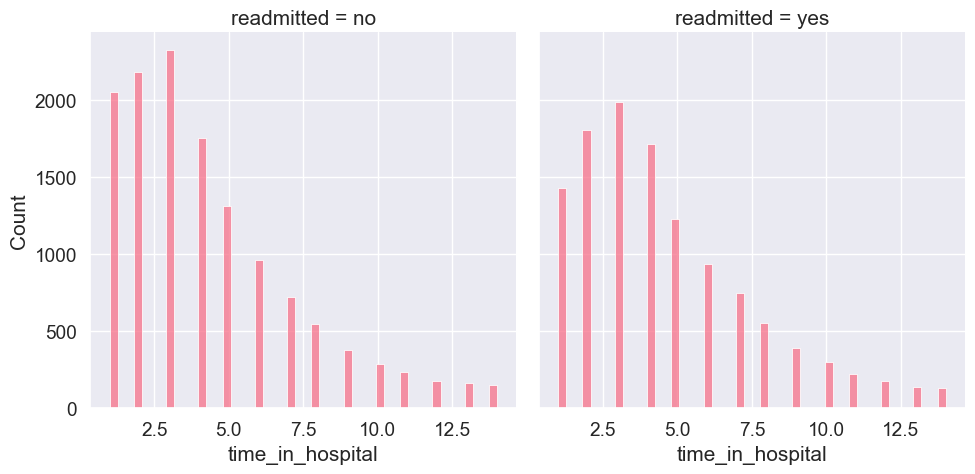

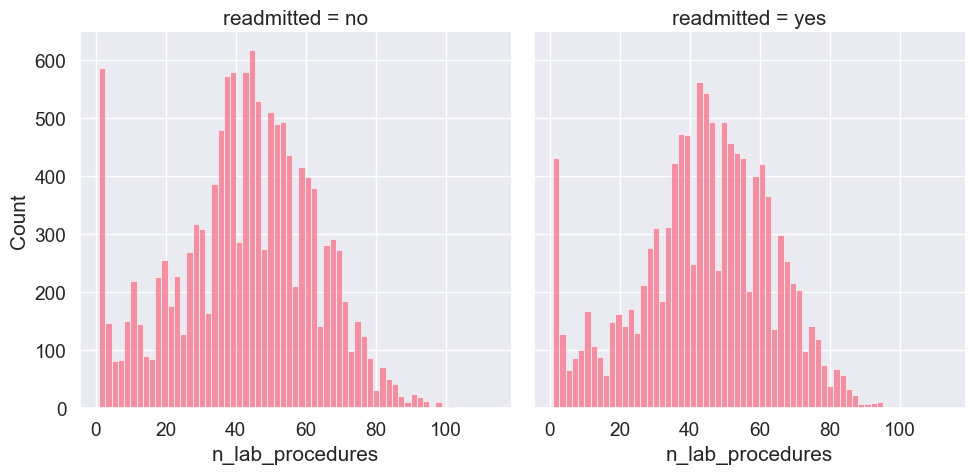

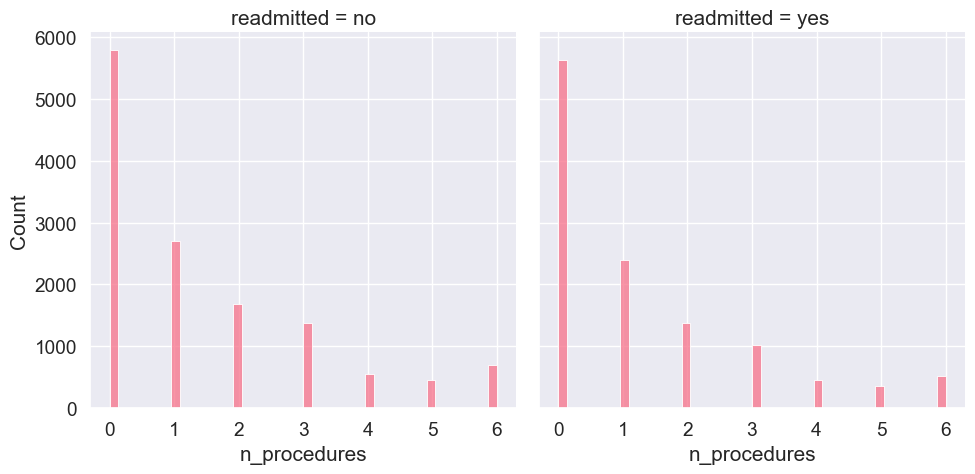

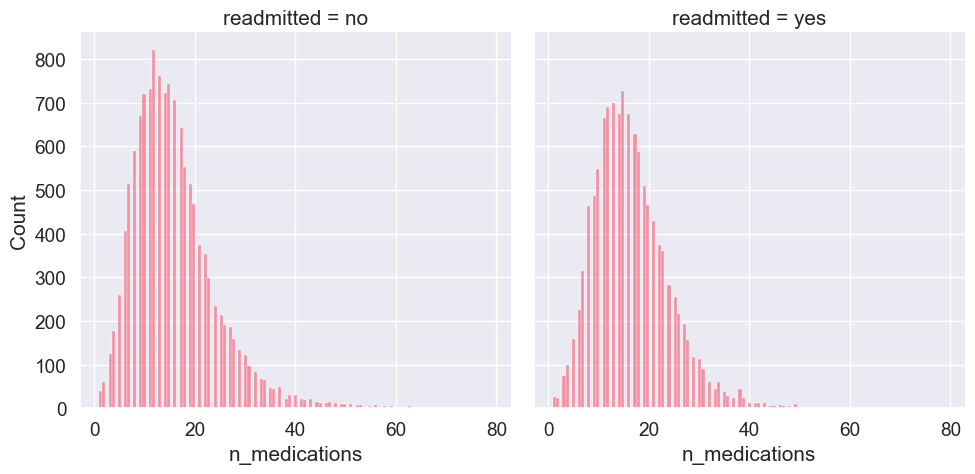

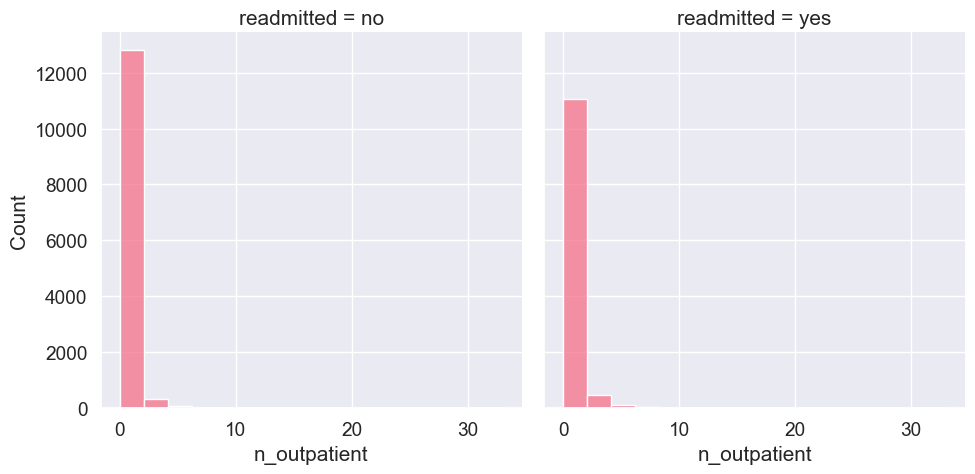

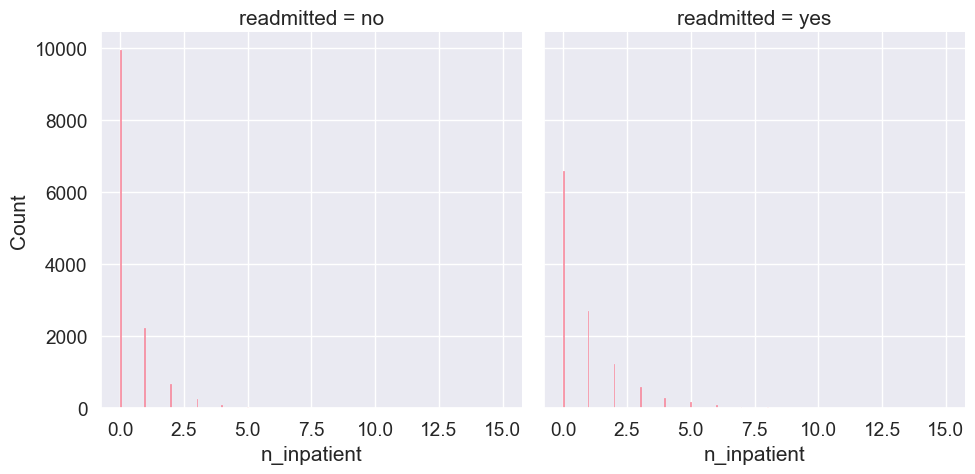

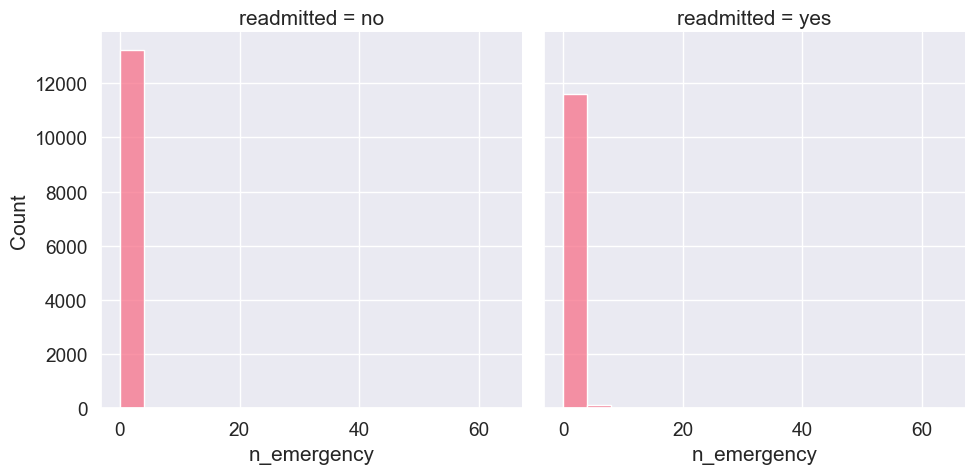

In [23]:
columns = ['time_in_hospital','n_lab_procedures','n_procedures','n_medications','n_outpatient','n_inpatient','n_emergency']

sns.set(style='darkgrid',font_scale=1.25)
sns.set_palette('husl',3)

def plot_cat_count():
    for c in columns:
        sns.displot(x=c, data=hsp_df, col='readmitted',col_wrap=2)
        #plt.title(c)
        #plt.xticks(rotation=90)
        plt.show()

plot_cat_count()

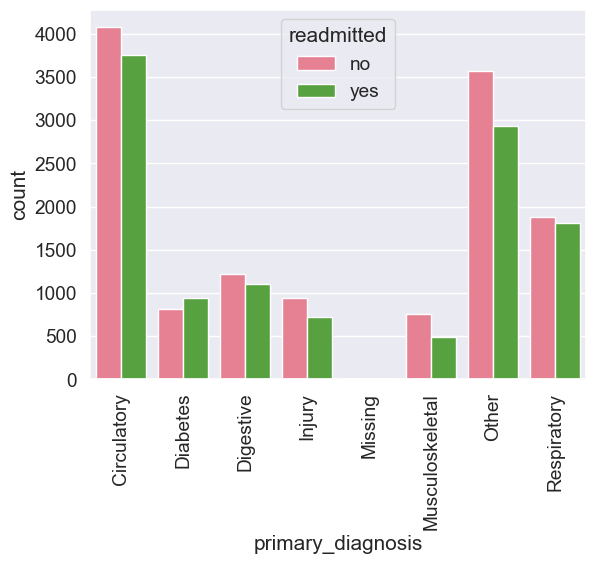

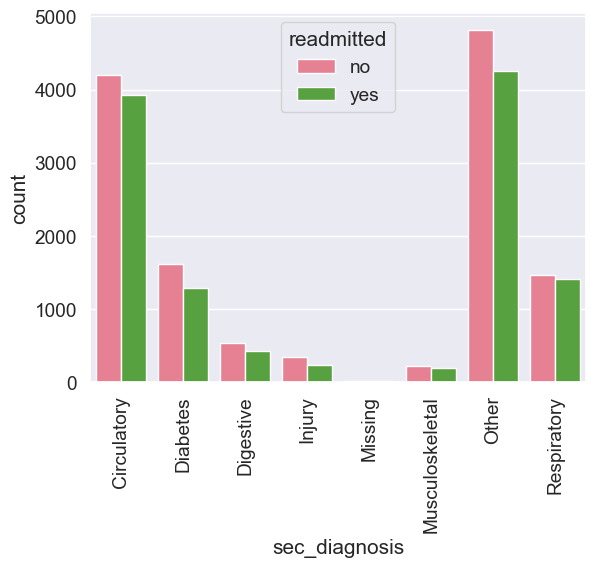

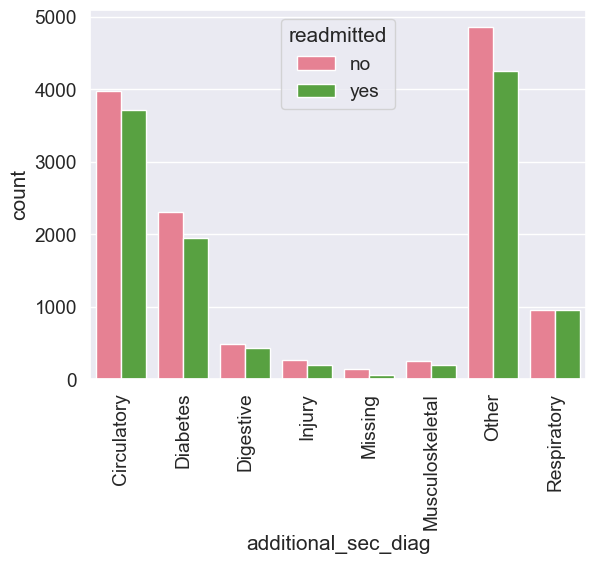

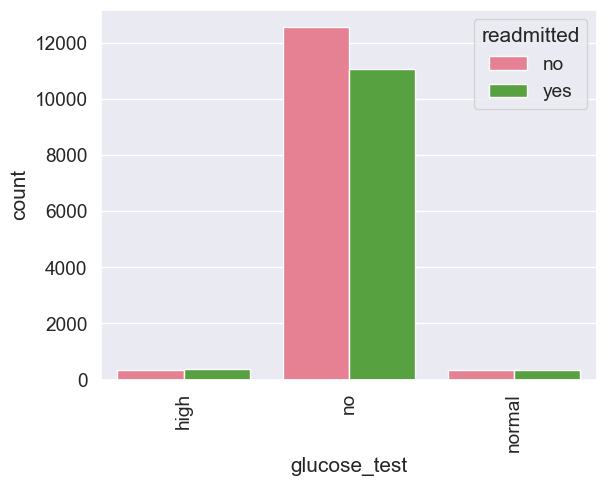

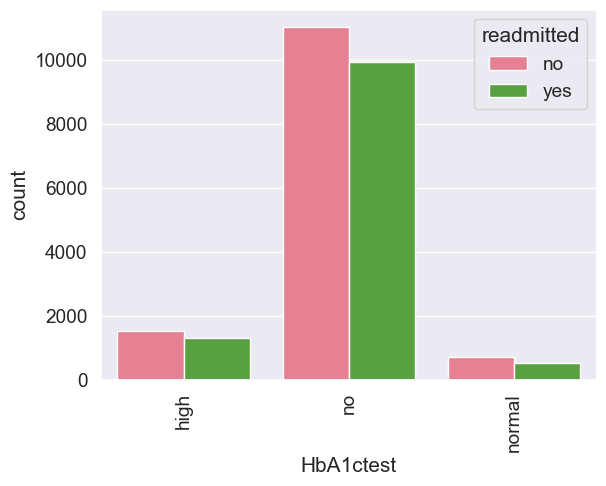

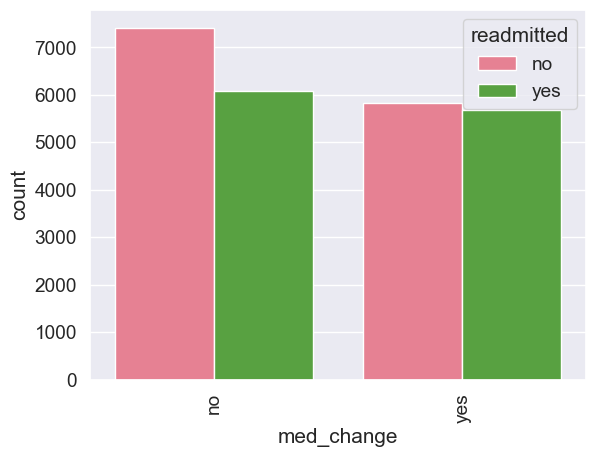

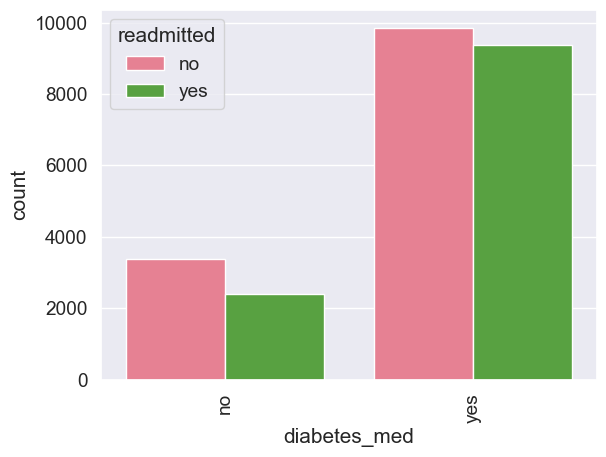

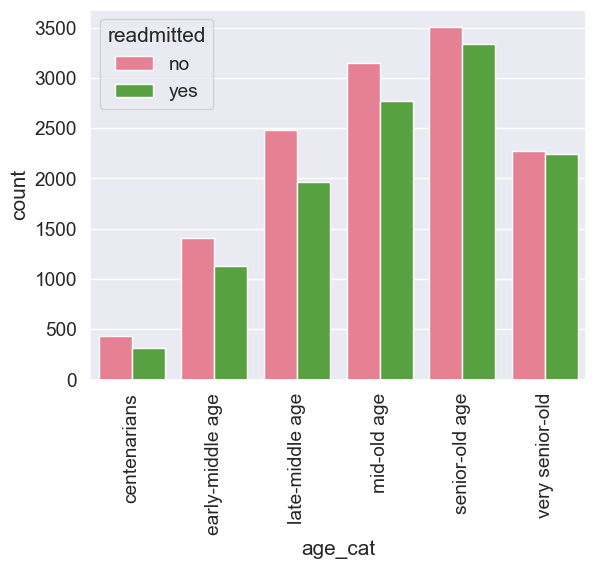

In [24]:
columns = ['primary_diagnosis', 'sec_diagnosis', 'additional_sec_diag', 
           'glucose_test', 'HbA1ctest', 'med_change', 'diabetes_med', 'age_cat']

def count_plot():
    for c in columns:
        sns.countplot(x=c, hue='readmitted', data=hsp_df)
        plt.xticks(rotation=90)
        plt.show()

count_plot()

In [25]:
#converting readmitted column to numerical
hsp_df['readmitted'] = np.where(hsp_df['readmitted']=='yes',1,0)

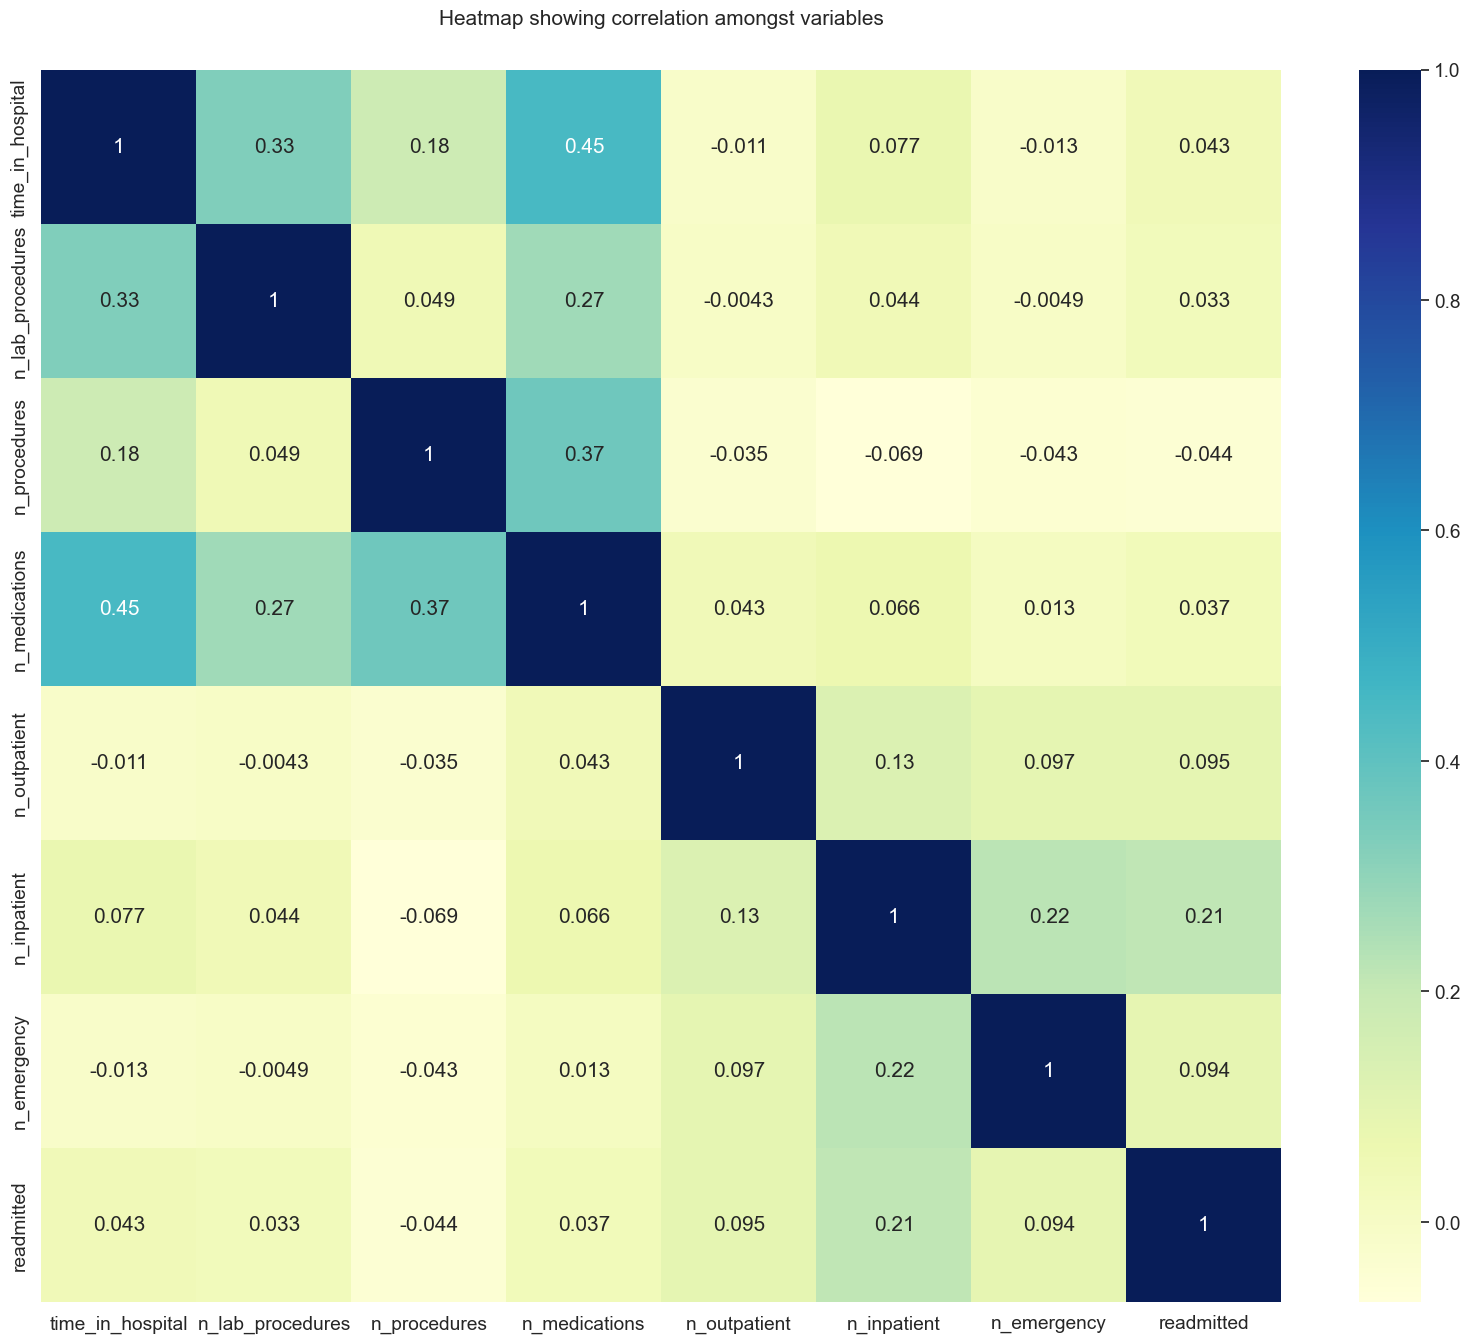

In [26]:
plt.figure(figsize=(20,16))
sns.heatmap(hsp_df.corr(numeric_only=True), cmap='YlGnBu', fmt='.2g', annot=True)

plt.title('Heatmap showing correlation amongst variables',y=1.03)
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [27]:
hsp_df.var(numeric_only=True)

time_in_hospital      9.008821
n_lab_procedures    392.777706
n_procedures          2.941840
n_medications        64.972173
n_outpatient          1.429168
n_inpatient           1.387569
n_emergency           0.784772
readmitted            0.249120
dtype: float64

In [28]:
features = hsp_df.drop(['medical_specialty', 'readmitted'], axis=1)
features

X_features = pd.get_dummies(features, columns =['primary_diagnosis', 'sec_diagnosis', 'additional_sec_diag',
             'glucose_test', 'HbA1ctest', 'med_change', 'diabetes_med', 'age_cat'])
X = X_features.values

y = hsp_df['readmitted'].values

print('X shape:', X.shape)

print('y shape:', y.shape)

X shape: (25000, 47)
y shape: (25000,)


In [29]:
hsp_df['readmitted'].value_counts()

readmitted
0    13246
1    11754
Name: count, dtype: int64

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import precision_score, recall_score, accuracy_score
from sklearn.preprocessing import StandardScaler

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,stratify=y,random_state=23)

In [31]:
names = X_features.columns

In [32]:
dtc = DecisionTreeClassifier(random_state=2, max_depth=3, min_samples_leaf=0.20)

dtc.fit(X_train, y_train)

test_predictions = dtc.predict(X_test)
train_prediction = dtc.predict(X_train)

acc_scoreX = accuracy_score(y_train, train_prediction)
print('Training_accuracy_score :', acc_scoreX)
acc_score = accuracy_score(y_test, test_predictions)
print('Testing_accuracy_score:', acc_score)
pre_score = precision_score(y_test, test_predictions)
print('precision_score:', pre_score)
rec_score = recall_score(y_test, test_predictions)
print('recall_score:',rec_score)

Training_accuracy_score : 0.6026857142857143
Testing_accuracy_score: 0.608
precision_score: 0.6168261562998405
recall_score: 0.4387407827566648


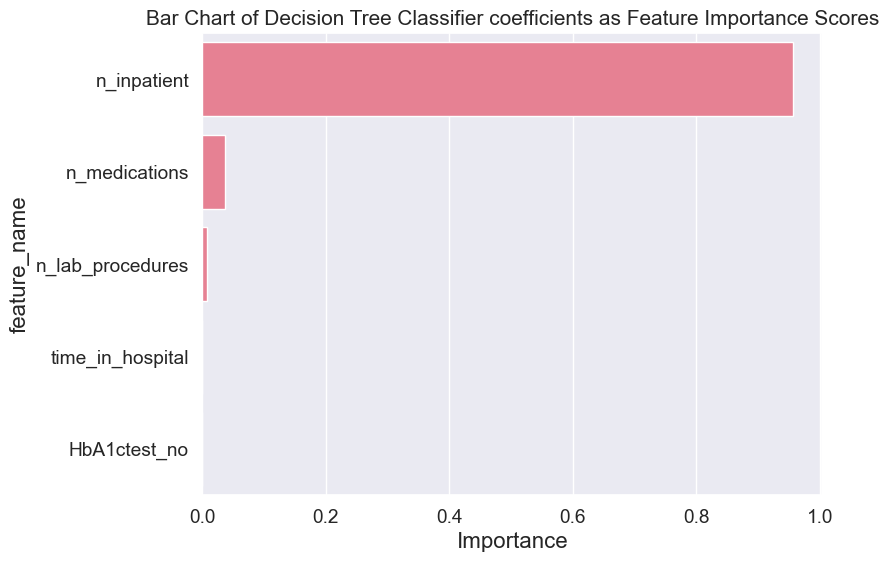

In [33]:
# get importance
importance = dtc.feature_importances_

#plot feature importance
imp_df = pd.DataFrame({'feature_name':names, 'Importance':importance})
fi = imp_df.sort_values(by='Importance', ascending=False).head()

#plot feature importance
plt.figure(figsize=(8,6))
sns.barplot(data=fi, x='Importance', y='feature_name')
plt.xlabel('Importance', fontsize=16)
plt.ylabel('feature_name', fontsize=16)
plt.title('Bar Chart of Decision Tree Classifier coefficients as Feature Importance Scores')
plt.show()

In [34]:
# define the model
rfc = RandomForestClassifier(random_state=23,n_estimators=100,max_depth=6)
# fit the model
rfc.fit(X_train, y_train)

test_predictions = rfc.predict(X_test)
train_prediction = rfc.predict(X_train)
#check model accuracy, precision and recall score
acc_scoreX = accuracy_score(y_train, train_prediction)
print('Training_accuracy_score:', acc_scoreX)
acc_score = accuracy_score(y_test, test_predictions)
print('Testing_accuracy_score :', acc_score)
pre_score = precision_score(y_test, test_predictions)
print('precision_score :', pre_score)
rec_score = recall_score(y_test, test_predictions)
print('recall_score :', rec_score)

Training_accuracy_score: 0.6304
Testing_accuracy_score : 0.6104
precision_score : 0.6183385579937304
recall_score : 0.44753261486103235


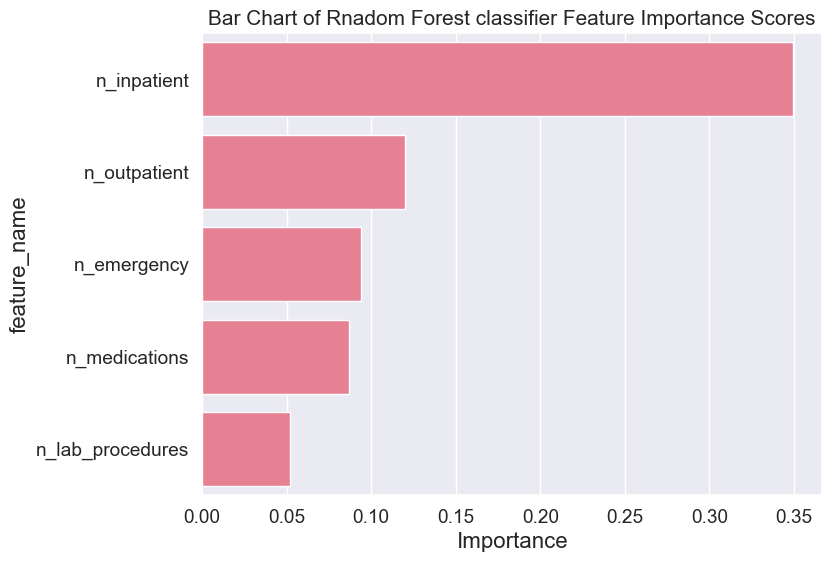

In [35]:
# get importance
importance = rfc.feature_importances_

imp_df = pd.DataFrame({'feature_name':names, 'Importance':importance})
fi = imp_df.sort_values(by='Importance', ascending=False).head()

#plot feature importance
plt.figure(figsize=(8,6))
sns.barplot(data=fi, x= 'Importance', y='feature_name')
plt.xlabel('Importance', fontsize=16)
plt.ylabel('feature_name', fontsize=16)
plt.title('Bar Chart of Rnadom Forest classifier Feature Importance Scores')
plt.show()

In [36]:
#inspecting the hyperparameters of the randomforestclassifier
print(rfc.get_params())

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 6, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 23, 'verbose': 0, 'warm_start': False}


In [37]:
from sklearn.model_selection import GridSearchCV
rfc = RandomForestClassifier(random_state=23)

params_rfc = {'max_depth':[3,6,8], 'min_samples_leaf':[0.04, 0.08, 1], 'max_features':['sqrt','log2']}

grid_rfc = GridSearchCV(estimator=rfc, param_grid=params_rfc, scoring='accuracy', cv=10, n_jobs=-1)
grid_rfc.fit(X_train, y_train)

#extract best hyperparameters from grid_rfc
best_hyperparams = grid_rfc.best_params_
print("best_hyperparams: ", best_hyperparams)

#extract best cv score
best_cv_score = grid_rfc.best_score_
print("best_cv_score: ", best_cv_score)

#extract best model
best_model = grid_rfc.best_estimator_
print("best_model: ", best_model)

#evaluate test set accuracy
test_acc = best_model.score(X_test, y_test)
print("test_acc: ", test_acc)

best_hyperparams:  {'max_depth': 8, 'max_features': 'log2', 'min_samples_leaf': 1}
best_cv_score:  0.6143428571428571
best_model:  RandomForestClassifier(max_depth=8, max_features='log2', random_state=23)
test_acc:  0.612


In [38]:
# define the model
rfc2 = RandomForestClassifier(random_state=23, max_depth=8, max_features='log2', min_samples_leaf=1)
# fit the model
rfc2.fit(X_train, y_train)

test_predictions = rfc2.predict(X_test)
train_prediction = rfc2.predict(X_train)
#check model accuracy, precision and recall score
acc_scoreX = accuracy_score(y_train, train_prediction)
print('Training_accuracy_score :', acc_scoreX)
acc_score = accuracy_score(y_test, test_predictions)
print('Testing_accuracy_score :', acc_score)
pre_score = precision_score(y_test, test_predictions)
print('precision_score :', pre_score)
rec_score = recall_score(y_test, test_predictions)
print('recall_score :', rec_score)

Training_accuracy_score : 0.6499428571428572
Testing_accuracy_score : 0.612
precision_score : 0.6209740769835035
recall_score : 0.4483834373227453


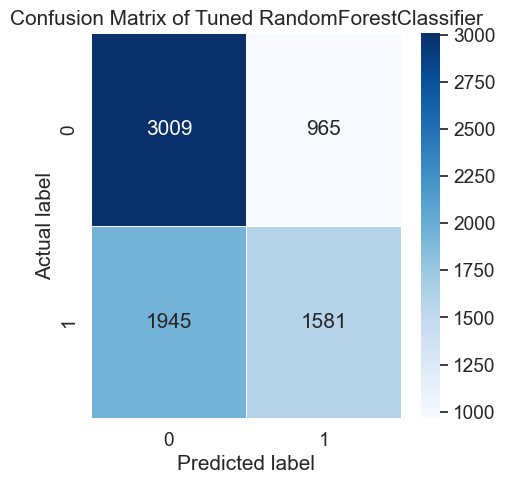

In [39]:
from sklearn.metrics import classification_report, confusion_matrix
cm = confusion_matrix(y_test, test_predictions)
plt.figure(figsize=(5,5))
sns.heatmap(data=cm, linewidth=.5, annot=True, fmt='d', cmap='Blues')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Confusion Matrix of Tuned RandomForestClassifier')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

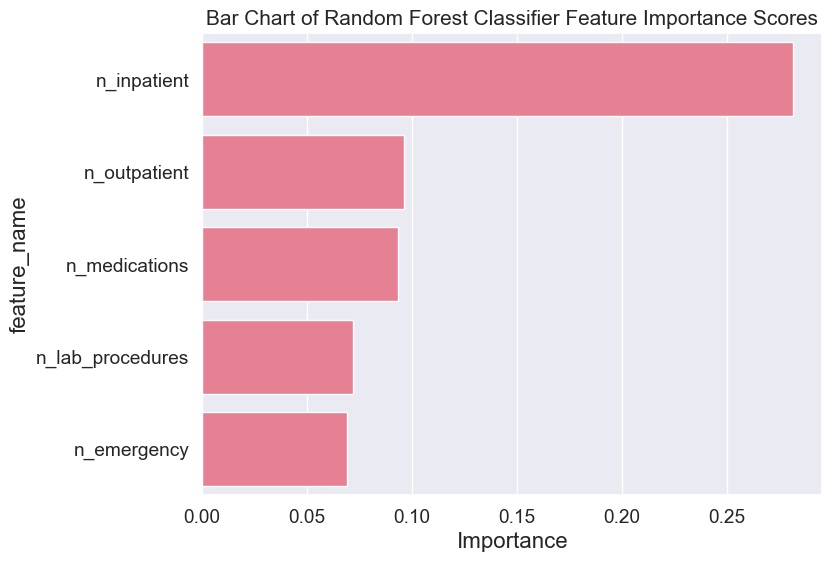

In [40]:
# get importance
importance = rfc2.feature_importances_

imp_df = pd.DataFrame({'feature_name':names, 'Importance':importance})
fi = imp_df.sort_values(by='Importance', ascending=False).head()

# plot feature importance
plt.figure(figsize=(8,6))
sns.barplot(data=fi, x='Importance', y='feature_name')
plt.xlabel('Importance', fontsize=16)
plt.ylabel('feature_name', fontsize=16)
plt.title('Bar Chart of Random Forest Classifier Feature Importance Scores')
plt.show()

In [41]:
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

Xt = pd.DataFrame(X_test, columns=names)

def evaluate(name, pred, proba=None):
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {'Model': name,
            'Accuracy': round((tp + tn) / len(y_test), 4),
            'Sensitivity': round(tp / (tp + fn), 4),
            'Specificity': round(tn / (tn + fp), 4),
            'ROC AUC': round(roc_auc_score(y_test, proba), 4) if proba is not None else None,
            'Missed readmissions': fn}

rule = (Xt['n_inpatient'].astype(float) >= 1).astype(int).values

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(X_train.astype(float), y_train)

rows = [
    evaluate('Always predict "no"', np.zeros(len(y_test), dtype=int)),
    evaluate('Rule: 1+ prior inpatient visit', rule),
    evaluate('Logistic Regression', lr.predict(X_test.astype(float)), lr.predict_proba(X_test.astype(float))[:, 1]),
    evaluate('Tuned Random Forest', rfc2.predict(X_test), rfc2.predict_proba(X_test)[:, 1]),
]
pd.DataFrame(rows)

,Model,Accuracy,Sensitivity,Specificity,ROC AUC,Missed readmissions
0,"Always predict ""no""",0.5299,0.0000,1.0000,NaN,3526
1,Rule: 1+ prior inpatient visit,0.6080,0.4387,0.7582,NaN,1979
2,Logistic Regression,0.6080,0.3999,0.7927,0.6425,2116
3,Tuned Random Forest,0.6120,0.4484,0.7572,0.6529,1945


In [42]:
for col in ['n_inpatient', 'n_emergency', 'n_outpatient']:
    t = hsp_df.groupby(hsp_df[col].clip(upper=4))['readmitted'].agg(['mean', 'size'])
    t.columns = ['Readmission rate (%)', 'Patients']
    t['Readmission rate (%)'] = (t['Readmission rate (%)'] * 100).round(1)
    print(f'\n{col} (4 = 4 or more visits)')
    print(t)


n_inpatient (4 = 4 or more visits)
             Readmission rate (%)  Patients
n_inpatient                                
0                            39.9     16537
1                            54.7      4926
2                            64.6      1909
3                            70.3       833
4                            81.3       795

n_emergency (4 = 4 or more visits)
             Readmission rate (%)  Patients
n_emergency                                
0                            45.1     22272
1                            59.0      1842
2                            65.3       525
3                            73.7       167
4                            84.5       194

n_outpatient (4 = 4 or more visits)
              Readmission rate (%)  Patients
n_outpatient                                
0                             44.4     20859
1                             58.4      2076
2                             62.7       913
3                             56.8       537
4    

In [43]:
y_proba = rfc2.predict_proba(X_test)[:, 1]
rows = []
for t in [0.5, 0.45, 0.4]:
    p = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({'Threshold': t,
                 'Sensitivity': round(tp / (tp + fn), 4),
                 'Specificity': round(tn / (tn + fp), 4),
                 'Missed readmissions': fn,
                 'Extra patients flagged': fp})
pd.DataFrame(rows)

,Threshold,Sensitivity,Specificity,Missed readmissions,Extra patients flagged
0,0.50,0.4484,0.7572,1945,965
1,0.45,0.6339,0.5908,1291,1626
2,0.40,0.8571,0.2796,504,2863


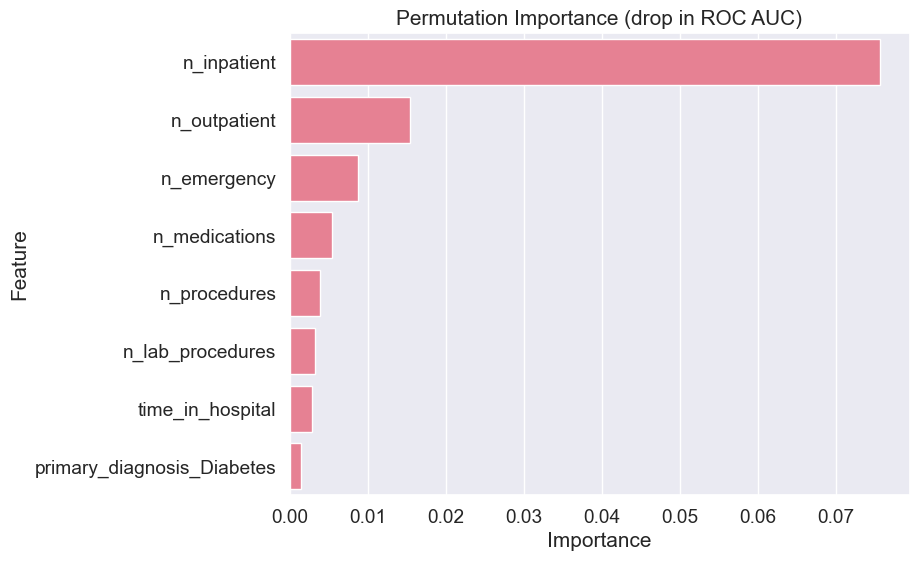

,Feature,Importance
5,n_inpatient,0.075593
4,n_outpatient,0.015488
6,n_emergency,0.008757
3,n_medications,0.005391
2,n_procedures,0.003945
1,n_lab_procedures,0.003263
0,time_in_hospital,0.002879
8,primary_diagnosis_Diabetes,0.001489


In [44]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rfc2, X_test, y_test, scoring='roc_auc',
                              n_repeats=5, random_state=23, n_jobs=-1)
perm_df = (pd.DataFrame({'Feature': names, 'Importance': perm.importances_mean})
           .sort_values('Importance', ascending=False))

plt.figure(figsize=(8, 6))
sns.barplot(data=perm_df.head(8), x='Importance', y='Feature')
plt.title('Permutation Importance (drop in ROC AUC)')
plt.savefig('permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

perm_df.head(8)